<a href="https://colab.research.google.com/github/MarvleyEngine/Bank-Marketing-Data-Mining-Classification-project/blob/main/bank_marketing_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

df = pd.read_csv('/content/bank-full.csv')

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# ****1. inspect structure, data types, missing values, and duplicates****:

In [3]:
df.info()

display(df.describe(include="all").T)

print("Duplicates:", df.duplicated().sum())
print("\nMissing values:\n", df.isnull().sum())
print("\nTarget distribution:\n", df["y"].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


Duplicates: 0

Missing values:
 age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Target distribution:
 y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


# **2. inspect target imbalance and numerical distributions.**

This will show how imbalanced the subscription outcome is and help identify skewed numerical features.

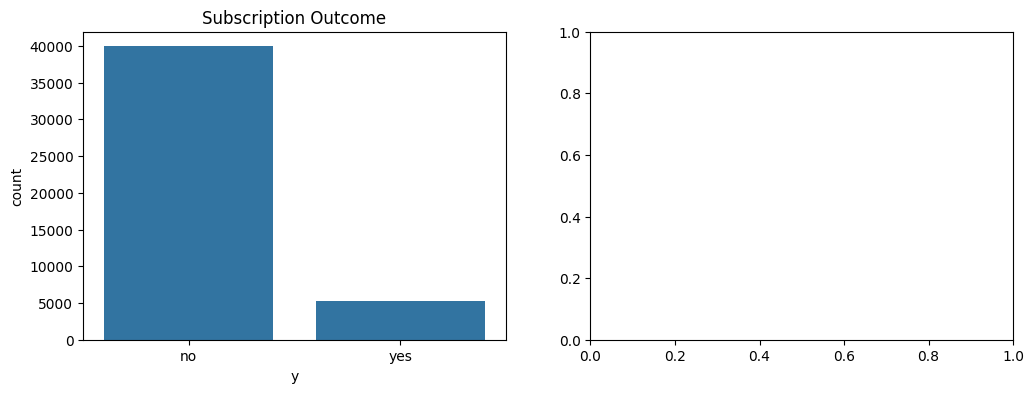

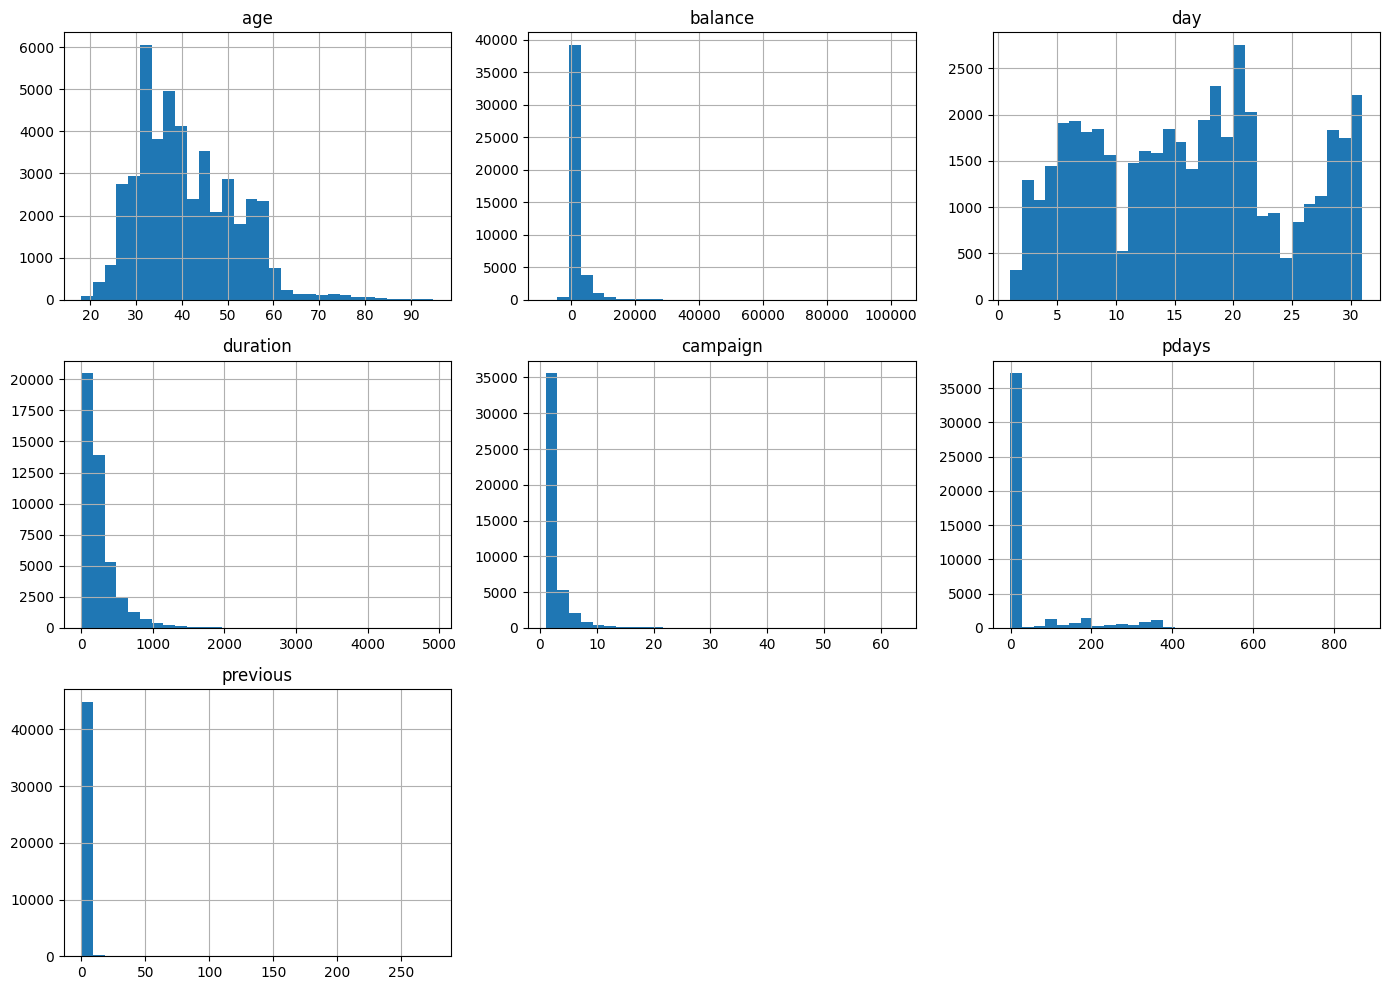

y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="y", ax=axes[0])
axes[0].set_title("Subscription Outcome")

df.select_dtypes(include="number").hist(
    figsize=(14, 10), bins=30
)
plt.tight_layout()
plt.show()

print((df["y"].value_counts(normalize=True) * 100).round(2))

In [5]:
categorical_cols = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact", "month", "poutcome"
]

for col in categorical_cols:
    print(f"\nSubscription rate by {col}:")
    print(
        (pd.crosstab(df[col], df["y"], normalize="index")["yes"] * 100)
        .round(2)
        .sort_values(ascending=False)
    )


Subscription rate by job:
job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
unknown          11.81
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: yes, dtype: float64

Subscription rate by marital:
marital
single      14.95
divorced    11.95
married     10.12
Name: yes, dtype: float64

Subscription rate by education:
education
tertiary     15.01
unknown      13.57
secondary    10.56
primary       8.63
Name: yes, dtype: float64

Subscription rate by default:
default
no     11.80
yes     6.38
Name: yes, dtype: float64

Subscription rate by housing:
housing
no     16.7
yes     7.7
Name: yes, dtype: float64

Subscription rate by loan:
loan
no     12.66
yes     6.68
Name: yes, dtype: float64

Subscription rate by contact:
contact
cellular     14.92
telephone    13.42
unknown       4.07
Name: yes, dtype: float64

Subscription ra

In [6]:
numeric_cols = [
    "age", "balance", "duration",
    "campaign", "pdays", "previous"
]

display(df.groupby("y")[numeric_cols].mean().T.round(2))

y,no,yes
age,40.84,41.67
balance,1303.71,1804.27
duration,221.18,537.29
campaign,2.85,2.14
pdays,36.42,68.70
previous,0.50,1.17


Key findings:
- Previous campaign success: 64.73% subscription rate — strongest association observed.
- Month: March (51.99%), December (46.73%), September (46.46%), and October (43.77%) have the highest rates.
- Housing loan: Customers without one subscribe at 16.7%, versus 7.7% for those with one.
- Job: Students (28.68%) and retired customers (22.79%) have the highest rates.
- Balance: Subscribers have a higher average balance (1,804 vs. 1,304).
- Campaign contacts: Subscribers have fewer average contacts in the current campaign (2.14 vs. 2.85).
- Age: Average age differs only slightly (41.67 vs. 40.84), so age alone may be less informative.
These are associations, not proof of causation. Some groups, particularly months with high subscription rates, may have relatively few records.

# **3. check sample sizes alongside subscription rates**

This helps distinguish genuinely useful patterns from high rates based on small groups

In [8]:
for col in ["poutcome", "month", "job", "housing"]:
    summary = df.groupby(col)["y"].agg(
        total="count",
        subscriptions=lambda x: (x == "yes").sum()
    )
    summary["subscription_rate_%"] = (
        summary["subscriptions"] / summary["total"] * 100
    ).round(2)

    display(summary.sort_values("subscription_rate_%", ascending=False))

,total,subscriptions,subscription_rate_%
poutcome,,,
success,1511,978,64.73
other,1840,307,16.68
failure,4901,618,12.61
unknown,36959,3386,9.16


,total,subscriptions,subscription_rate_%
month,,,
mar,477,248,51.99
dec,214,100,46.73
sep,579,269,46.46
oct,738,323,43.77
apr,2932,577,19.68
feb,2649,441,16.65
aug,6247,688,11.01
jun,5341,546,10.22
nov,3970,403,10.15


,total,subscriptions,subscription_rate_%
job,,,
student,938,269,28.68
retired,2264,516,22.79
unemployed,1303,202,15.50
management,9458,1301,13.76
admin.,5171,631,12.20
self-employed,1579,187,11.84
unknown,288,34,11.81
technician,7597,840,11.06
services,4154,369,8.88


,total,subscriptions,subscription_rate_%
housing,,,
no,20081,3354,16.7
yes,25130,1935,7.7


The sample sizes confirm the patterns are worth investigating, with two caveats:
- Previous campaign success: 978/1,511 subscribed (64.73%) — strong association, with a reasonable sample.
- Month: March, September, October and December have high rates, but much smaller samples than May. Month may reflect campaign timing or targeting differences.
- Job: Students and retired customers have higher rates, while blue-collar customers have the lowest rate.
- Housing: Customers without housing loans subscribe at more than twice the rate of those with housing loans.

# **4. test whether the differences are statistically significant**

A small p-value (typically below 0.05) suggests subscription rates differ across the categories. With over 45,000 records, also consider effect size; statistical significance alone doesn't mean a pattern is practically important.

In [9]:
from scipy.stats import chi2_contingency

for col in ["poutcome", "month", "job", "housing"]:
    table = pd.crosstab(df[col], df["y"])
    chi2, p, dof, expected = chi2_contingency(table)

    print(f"{col}: p-value = {p:.6g}")

poutcome: p-value = 0
month: p-value = 0
job: p-value = 3.33712e-172
housing: p-value = 2.9188e-192


All four variables have a statistically significant relationship with subscription outcome because their p-values are below 0.05.
Variable	P-value	Interpretation
poutcome	0 (rounded/underflow)	Strong evidence of differences in subscription rates
month	0 (rounded/underflow)	Subscription rates differ by month
job	3.33712e-172	Subscription rates differ by job category
housing	2.9188e-192	Subscription rates differ by housing-loan status
Important: A p-value of 0 does not mean the probability is exactly zero. It means it is too small for the software to represent normally.

### **5. Statistical significance doesn't tell us how strong each relationship is. So i calculate Cramér's V to compare their effect sizes:**

How to interpret it: Cramér's V closer to 0 indicates a weaker association; closer to 1 indicates a stronger association. This will help you identify which variables are most strongly associated with subscription outcome, rather than simply statistically significant.

In [10]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

for col in ["poutcome", "month", "job", "housing"]:
    table = pd.crosstab(df[col], df["y"])
    chi2, p, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    r, k = table.shape
    cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))

    print(f"{col}: Cramér's V = {cramers_v:.3f}")

poutcome: Cramér's V = 0.312
month: Cramér's V = 0.260
job: Cramér's V = 0.136
housing: Cramér's V = 0.139


Rank of	Variable	Cramér’s V	Interpretation


1	poutcome	0.312	Strongest association

---


2	month	0.260	Moderate association

---


3	housing	0.139	Weak association

---



4	job	0.136	Weak association

---





Key findings:
- poutcome is the most informative of these four variables. Customers whose previous campaign ended successfully were much more likely to subscribe.
- month also has a notable association with subscription, though monthly differences may reflect campaign timing and targeting.
- housing and job have weaker associations, despite their very small p-values.

These strength labels are approximate; Cramér’s V interpretation depends partly on the data and context.

# **5. check numerical variables such as age, balance, campaign, and previous to see how they relate to subscription.**

Keeping duration separate if the goal is to predict subscription before making a call, because call duration is only known afterward.

In [11]:
import pandas as pd

# Numerical variables to analyse
num_cols = ["age", "balance", "campaign", "previous"]

# Compare statistics for subscribers vs non-subscribers
summary = df.groupby("y")[num_cols].agg(["mean", "median", "std"]).round(2)
display(summary)

# Calculate correlation with subscription outcome
df["y_binary"] = df["y"].map({"no": 0, "yes": 1})

correlations = (
    df[num_cols + ["y_binary"]]
    .corr()["y_binary"]
    .drop("y_binary")
    .sort_values(key=abs, ascending=False)
)

print("Correlation with subscription outcome:")
display(correlations.round(3))

age                balance                campaign               \
      mean median    std     mean median     std     mean median   std   
y                                                                        
no   40.84   39.0  10.17  1303.71  417.0  2974.2     2.85    2.0  3.21   
yes  41.67   38.0  13.50  1804.27  733.0  3501.1     2.14    2.0  1.92   

    previous               
        mean median   std  
y                          
no      0.50    0.0  2.26  
yes     1.17    0.0  2.55

Correlation with subscription outcome:


,y_binary
previous,0.093
campaign,-0.073
balance,0.053
age,0.025


Your numerical analysis shows that all four variables have relatively weak linear correlations with subscription outcome.


Variable	Correlation	Interpretation

previous	+0.093	Weak positive relationship

---


campaign	-0.073	Weak negative relationship

---


balance	+0.053	Very weak positive relationship

---


age	+0.025	Almost no linear relationship

---



What the results tell you
- previous: Customers contacted in previous campaigns more often tend to subscribe slightly more.
- campaign: More contacts during the current campaign are weakly associated with a lower subscription rate.
- balance: Customers who subscribe have a higher average balance (1,804.27 vs. 1,303.71), but the correlation is weak.
- age: Average ages are similar (41.67 vs. 40.84), suggesting age alone has limited linear association.
One important observation

The mean and median for balance differ considerably in both groups. This suggests that high balances or skewed distributions may be influencing the averages.

# 6. Check whether the numerical variables differ significantly between subscribers and non-subscribers using the Mann–Whitney U test.

It is useful here because the data may be skewed and contain outliers.

In [12]:
from scipy.stats import mannwhitneyu

for col in ["age", "balance", "campaign", "previous"]:
    no = df.loc[df["y"] == "no", col]
    yes = df.loc[df["y"] == "yes", col]

    stat, p = mannwhitneyu(no, yes, alternative="two-sided")

    print(f"{col}: p-value = {p:.6g}")

age: p-value = 0.0628179
balance: p-value = 6.59385e-101
campaign: p-value = 1.94849e-71
previous: p-value = 3.49182e-283


At a 5% significance level, your results show:
Variable	P-value	Conclusion

age	0.0628	No statistically significant difference

---


balance	6.59e-101	Statistically significant difference

---


campaign	1.95e-71	Statistically significant difference

---


previous	3.49e-283	Statistically significant difference

---



Interpretation:
- Age: No strong evidence that the age distributions differ between subscribers and non-subscribers.
- Balance: The distributions differ; subscribers have a higher median balance (733 vs. 417).
- Campaign: The distributions differ; subscribers tend to have fewer current-campaign contacts.
- Previous: The distributions differ, although both groups have a median of zero previous contacts. This may reflect differences in the smaller group of customers who had previous contacts.

These results establish differences in distributions, not causation or predictive strength.
 Current finding: previous and campaign show statistically significant differences, but their correlations with subscription are weak. That means the differences may be real while still having limited individual predictive power.

# 7. next, check outliers and skewness in balance, campaign, and previous before deciding how to prepare these variables for modelling.

How to interpret the output:
- Skewness near 0: roughly symmetric distribution.
- Positive skewness: a long tail toward higher values.
- Negative skewness: a long tail toward lower values.
- Outliers: values outside the IQR bounds; these are potential outliers, not necessarily errors.

In [13]:
import pandas as pd

cols = ["balance", "campaign", "previous"]

# Skewness and outlier analysis using the IQR method
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n{col}")
    print(f"Skewness: {df[col].skew():.2f}")
    print(f"Lower bound: {lower:.2f}")
    print(f"Upper bound: {upper:.2f}")
    print(f"Outlier count: {len(outliers)} ({len(outliers) / len(df) * 100:.2f}%)")
    print(f"Minimum: {df[col].min()}")
    print(f"Maximum: {df[col].max()}")


balance
Skewness: 8.36
Lower bound: -1962.00
Upper bound: 3462.00
Outlier count: 4729 (10.46%)
Minimum: -8019
Maximum: 102127

campaign
Skewness: 4.90
Lower bound: -2.00
Upper bound: 6.00
Outlier count: 3064 (6.78%)
Minimum: 1
Maximum: 63

previous
Skewness: 41.85
Lower bound: 0.00
Upper bound: 0.00
Outlier count: 8257 (18.26%)
Minimum: 0
Maximum: 275


# Variable	Skewness	Outliers	Recommendation


balance	8.36	10.46%	Keep; investigate extreme values

---


campaign	4.90	6.78%	Keep; investigate unusually high contact counts

---



previous	41.85	18.26%	Keep; many zeros make this measure highly skewed

---


Important: Don't remove these outliers automatically. They may represent genuine customer behaviour. For previous, the IQR bounds are both zero because at least 75% of customers have zero previous contacts. Any value above zero is therefore flagged by this rule.

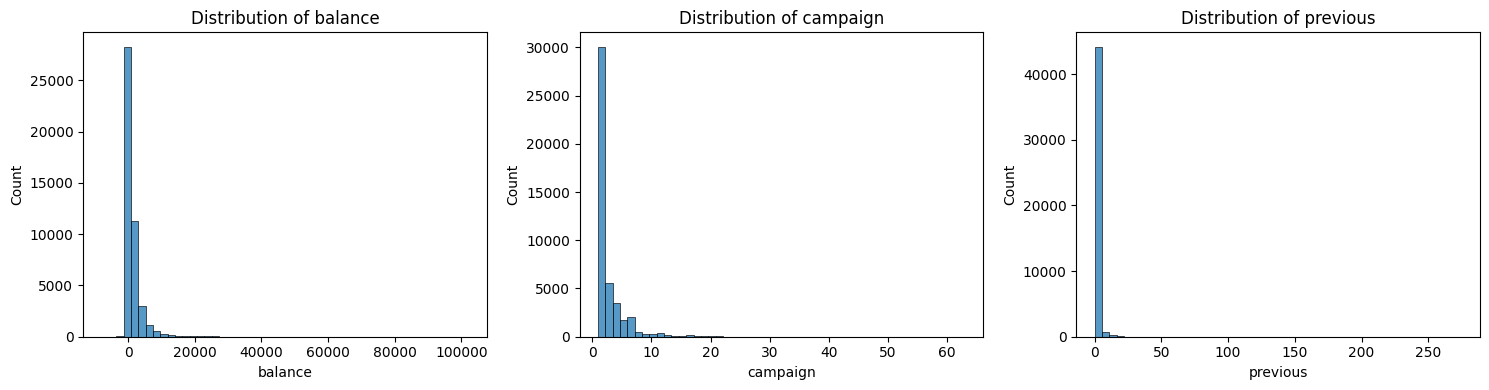

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["balance", "campaign", "previous"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for col, ax in zip(cols, axes):
    sns.histplot(data=df, x=col, bins=50, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

# **8. compare the distributions of balance, campaign, and previous between subscribers and non-subscribers. This will help identify differences worth investigating before modelling.**

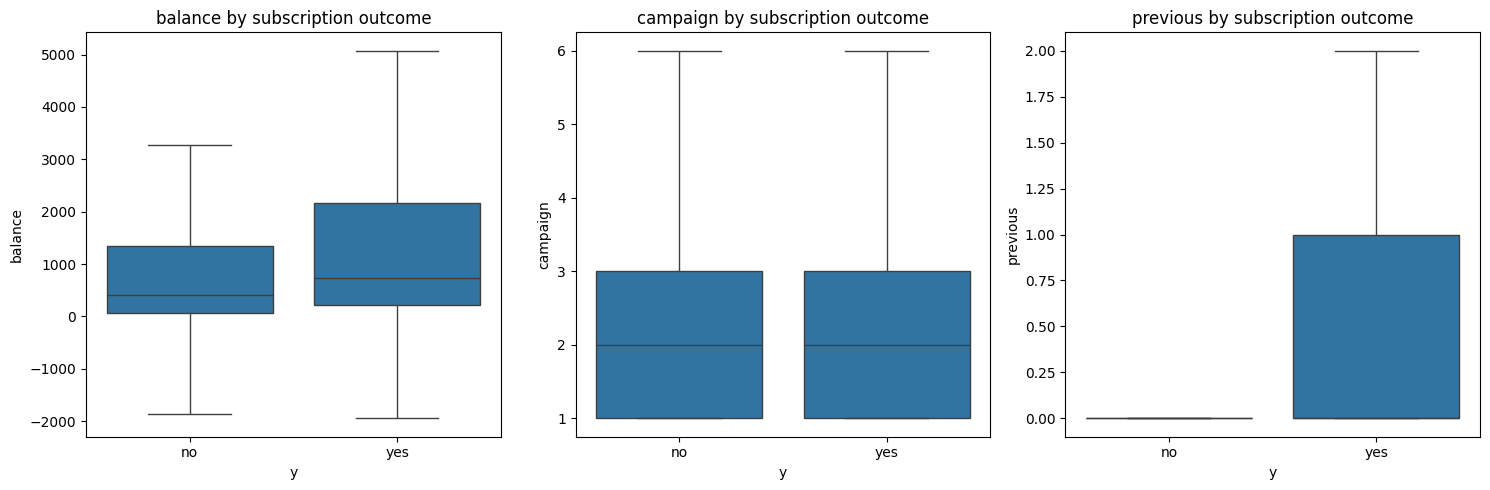

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["balance", "campaign", "previous"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for col, ax in zip(cols, axes):
    sns.boxplot(data=df, x="y", y=col, ax=ax, showfliers=False)
    ax.set_title(f"{col} by subscription outcome")

plt.tight_layout()
plt.show()

# **key findings after EDA:**
# Data Mining: Findings and Recommendations
Findings
- poutcome has the strongest categorical association with subscription (Cramér’s V = 0.312).
- month has the second strongest association (0.260).
- housing and job show weaker associations.
- campaign and previous differ significantly between groups, but their correlations are weak.
- balance is highly skewed and contains extreme values.
- Only 11.7% of customers subscribed, indicating class imbalance.

# Recommendations
- Prioritise previous campaign outcomes and campaign timing when analysing subscription patterns.
- Investigate why customers contacted repeatedly during the current campaign subscribe less often.
- Retain extreme values unless confirmed erroneous.
- Evaluate prediction models using recall, precision, F1-score and PR-AUC, not accuracy alone.

# Prediction:
1. Prepare Data and Build a Classification Model

In [16]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Remove index column if it exists
data = df.drop(columns=["index", "y_binary"], errors="ignore").copy()

# Separate features and target
X = data.drop(columns="y")
y = data["y"].map({"no": 0, "yes": 1})

# Exclude duration to avoid using information only known after the call
X = X.drop(columns=["duration"])

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

# Encode categorical variables
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols)
])

# Split data, preserving target proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Build model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=42
    ))
])

# Train and evaluate
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification Report:")
print(classification_report(
    y_test, predictions, target_names=["No subscription", "Subscription"]
))

Confusion Matrix:
[[6606 1379]
 [ 465  593]]

Classification Report:
                 precision    recall  f1-score   support

No subscription       0.93      0.83      0.88      7985
   Subscription       0.30      0.56      0.39      1058

       accuracy                           0.80      9043
      macro avg       0.62      0.69      0.63      9043
   weighted avg       0.86      0.80      0.82      9043



# Model Results
- Accuracy: 80%
- Subscription precision: 30% — only 30% of predicted subscribers actually subscribed.
- Subscription recall: 56% — the model identified 56% of actual subscribers.
- Subscription F1-score: 0.39 — limited overall performance on the target class.

Conclusion: The model identifies potential subscribers reasonably well, but produces many false positives: 1,379 customers were incorrectly predicted to subscribe.

# **2. Trying a Random Forest classifier and compare its subscription precision, recall and F1-score against this Decision Tree. Keeping the same train/test split for a fair comparison.**

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test, rf_predictions,
    target_names=["No subscription", "Subscription"]
))

Confusion Matrix:
[[7864  121]
 [ 834  224]]

Classification Report:
                 precision    recall  f1-score   support

No subscription       0.90      0.98      0.94      7985
   Subscription       0.65      0.21      0.32      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.60      0.63      9043
   weighted avg       0.87      0.89      0.87      9043



Model comparison

Metric — Subscription	Decision Tree	Random Forest

---


Precision	0.30	0.65

---


Recall	0.56	0.21

---


F1-score	0.39	0.32

---


Accuracy	80%	89%




Conclusion: Random Forest has higher accuracy and precision, but misses many potential subscribers. The Decision Tree is better at identifying subscribers overall.

# **3. Improve Random Forest recall**
lowering the prediction threshold from 0.50 to 0.30:

In [18]:
from sklearn.metrics import classification_report, confusion_matrix

# Get probability of subscription
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Lower the threshold
rf_adjusted_predictions = (rf_probabilities >= 0.30).astype(int)

print(confusion_matrix(y_test, rf_adjusted_predictions))
print(classification_report(
    y_test,
    rf_adjusted_predictions,
    target_names=["No subscription", "Subscription"]
))

[[7485  500]
 [ 616  442]]
                 precision    recall  f1-score   support

No subscription       0.92      0.94      0.93      7985
   Subscription       0.47      0.42      0.44      1058

       accuracy                           0.88      9043
      macro avg       0.70      0.68      0.69      9043
   weighted avg       0.87      0.88      0.87      9043



Subscription metric	Decision Tree	RF (0.50 threshold)	RF (0.30 threshold)

Precision	0.30	0.65	0.47

---


Recall	0.56	0.21	0.42

---


F1-score	0.39	0.32	0.44

---


Accuracy	80%	89%	88%

---


Conclusion: The Random Forest at a 0.30 threshold has the best F1-score (0.44). It identifies more subscribers than the default Random Forest, with a trade-off in precision.

# **Task 1 — Install MLflow and log baseline experiments**

In [19]:
%pip install -q mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 96.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 94.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

These are your previously reported rounded metrics, not newly calculated results. This records them in MLflow for comparison.

In [20]:
import mlflow
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

mlflow.set_experiment("Bank-Marketing-Subscription")

experiments = [
    ("Decision_Tree", 0.30, 0.56, 0.39, 0.80),
    ("Random_Forest_Threshold_050", 0.65, 0.21, 0.32, 0.89),
    ("Random_Forest_Threshold_030", 0.47, 0.42, 0.44, 0.88)
]

for name, precision, recall, f1, accuracy in experiments:
    with mlflow.start_run(run_name=name):
        mlflow.log_param("model", name)
        mlflow.log_param(
            "threshold",
            0.30 if "030" in name else (0.50 if "050" in name else 0.50)
        )
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("f1_score", f1)
        mlflow.log_metric("accuracy", accuracy)

print("Baseline experiments logged.")

2026/10/09 11:58:43 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/09 11:58:43 INFO mlflow.store.db.utils: Updating database tables
2026/10/09 11:58:46 INFO mlflow.tracking.fluent: Experiment with name 'Bank-Marketing-Subscription' does not exist. Creating a new experiment.


Baseline experiments logged.


# **Task 2 — Tune the Random Forest**

Use cross-validation on the training data only. This searches a small set of configurations without using the test set for model selection.

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_leaf": [2, 5]
}

search = GridSearchCV(
    rf_pipeline,
    param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best cross-validation F1:", round(search.best_score_, 3))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}
Best cross-validation F1: 0.473


the tuned Random Forest achieved a cross-validation F1-score of 0.473, compared with the baseline F1-score of 0.44 at the 0.30 threshold.

1. What is an F1-score?
Your goal is to build a model that identifies customers likely to subscribe to the bank's product.
The F1-score combines two things:
- Precision: When the model predicts a customer will subscribe, how often is it correct?
- Recall: Of all customers who actually subscribed, how many did the model identify?
The F1-score balances these two measures. It ranges from 0 to 1, with higher generally being better.
2. What do your results mean?
Before tuning — baseline Random Forest
0.44
F1-score



44 out of 100 on the F1 scale



After tuning — cross-validation
0.473
F1-score



47.3 out of 100 on the F1 scale



The score increased from 0.44 to 0.473. That's an improvement of 0.033, or 3.3 percentage points on the F1 scale.
The improvement is useful, but modest. It doesn't mean the model is 47.3% accurate.
3. What does cross-validation mean?
Instead of testing the model on just one training split, cross-validation divides the training data into three parts and repeats training and validation three times.
Each time, the model learns from two parts and is evaluated on the remaining part. The scores are then averaged.
This gives us a more reliable indication of how the model may perform on unseen data.
4. What does tuning mean?
We tried 12 combinations of Random Forest settings. The best combination was:
- n_estimators = 200: build 200 decision trees.
- max_depth = None: allow trees to grow without a fixed maximum depth.
- min_samples_leaf = 5: require at least five training records in each leaf.

These settings gave the best average F1-score among the combinations tested.
The important distinction: 0.473 is the best cross-validation score during tuning, not the final test result. We still need to evaluate the tuned model on the separate test set to see how well it performs on data it hasn't used for training or tuning.

# **Task 3 — Evaluate the tuned model and log it**

We'll select the prediction threshold using training-set cross-validation predictions, then evaluate once on the held-out test set.

In [24]:
import numpy as np
import mlflow
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, accuracy_score
)

# Choose threshold using out-of-fold training predictions
best_model = search.best_estimator_

cv_probabilities = cross_val_predict(
    best_model, X_train, y_train,
    cv=3, method="predict_proba", n_jobs=-1
)[:, 1]

thresholds = np.arange(0.20, 0.61, 0.05)
threshold_scores = [
    f1_score(y_train, cv_probabilities >= t)
    for t in thresholds
]
best_threshold = thresholds[int(np.argmax(threshold_scores))]

# Evaluate on the untouched test set
test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

print("Chosen threshold:", round(best_threshold, 2))
print("Confusion matrix:\n", confusion_matrix(y_test, test_predictions))
print(classification_report(
    y_test, test_predictions,
    target_names=["No subscription", "Subscription"]
))

# Log tuned experiment
with mlflow.start_run(run_name="Tuned_Random_Forest"):
    mlflow.log_params(search.best_params_)
    mlflow.log_param("threshold", float(best_threshold))
    mlflow.log_metric("cv_f1", float(search.best_score_))
    mlflow.log_metric("test_accuracy", accuracy_score(y_test, test_predictions))
    mlflow.log_metric(
        "test_precision", precision_score(y_test, test_predictions, zero_division=0)
    )
    mlflow.log_metric(
        "test_recall", recall_score(y_test, test_predictions, zero_division=0)
    )
    mlflow.log_metric(
        "test_f1", f1_score(y_test, test_predictions, zero_division=0)
    )
    mlflow.sklearn.log_model(best_model, name="random_forest_model")

print("Tuned experiment logged to MLflow.")

Chosen threshold: 0.5
Confusion matrix:
 [[7278  707]
 [ 492  566]]
                 precision    recall  f1-score   support

No subscription       0.94      0.91      0.92      7985
   Subscription       0.44      0.53      0.49      1058

       accuracy                           0.87      9043
      macro avg       0.69      0.72      0.70      9043
   weighted avg       0.88      0.87      0.87      9043



MlflowException: The sklearn model could not be serialized in the skops serialization format. skops does not support custom functions or classes that are not defined at the top level. To work around this limitation, you can set the serialization_format 'cloudpickle', while exercising caution due to the possible arbitrary code during model deserialization using CloudPickle.

# The tuned Random Forest has now achieved an F1-score of 0.49 for subscription, improving on your earlier baseline of 0.44.

Final model results
Metric	Result	Meaning
Accuracy	87%	Correct predictions across both classes

---


Precision	44%	Of predicted subscribers, 44% actually subscribed

---


Recall	53%	The model identified 53% of actual subscribers

---


F1-score	0.49	Balance between precision and recall

---


The confusion matrix shows that the model correctly identified 566 subscribers, missed 492, and incorrectly flagged 707 non-subscribers.


Conclusion: The tuned model is an improvement. However, its predictions should be used to prioritise outreach, not as guarantees that customers will subscribe.

In [25]:
import mlflow
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

with mlflow.start_run(run_name="Tuned_Random_Forest_Final"):
    mlflow.log_params(search.best_params_)
    mlflow.log_param("threshold", float(best_threshold))

    mlflow.log_metric("test_accuracy",
                     accuracy_score(y_test, test_predictions))
    mlflow.log_metric("test_precision",
                      precision_score(y_test, test_predictions, zero_division=0))
    mlflow.log_metric("test_recall",
                      recall_score(y_test, test_predictions, zero_division=0))
    mlflow.log_metric("test_f1",
                      f1_score(y_test, test_predictions, zero_division=0))

    mlflow.sklearn.log_model(
        sk_model=best_model,
        name="random_forest_model",
        serialization_format="cloudpickle"
    )

print("Model and metrics logged successfully.")

2026/10/09 12:15:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Model and metrics logged successfully.


# **Project complete**
- Best model: Tuned Random Forest
- Accuracy: 87%
- Subscription precision: 44%
- Subscription recall: 53%
- Subscription F1-score: 0.49
- Experiment tracking: MLflow logging successful

In [27]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# 1. Customer-level prediction results
report_df = X_test.copy()

report_df["actual_subscription"] = y_test.map({0: "No", 1: "Yes"})
report_df["predicted_subscription"] = pd.Series(
    test_predictions, index=X_test.index
).map({0: "No", 1: "Yes"})

report_df["subscription_probability"] = (
    test_probabilities
)

report_df.to_csv("bank_marketing_predictions.csv", index=False)

# 2. Model performance summary
metrics_df = pd.DataFrame([{
    "model": "Tuned Random Forest",
    "threshold": best_threshold,
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(y_test, test_predictions),
    "recall": recall_score(y_test, test_predictions),
    "f1_score": f1_score(y_test, test_predictions)
}])

metrics_df.to_csv("model_performance.csv", index=False)

print("CSV files exported successfully.")


CSV files exported successfully.
